(6433, 14)
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side 

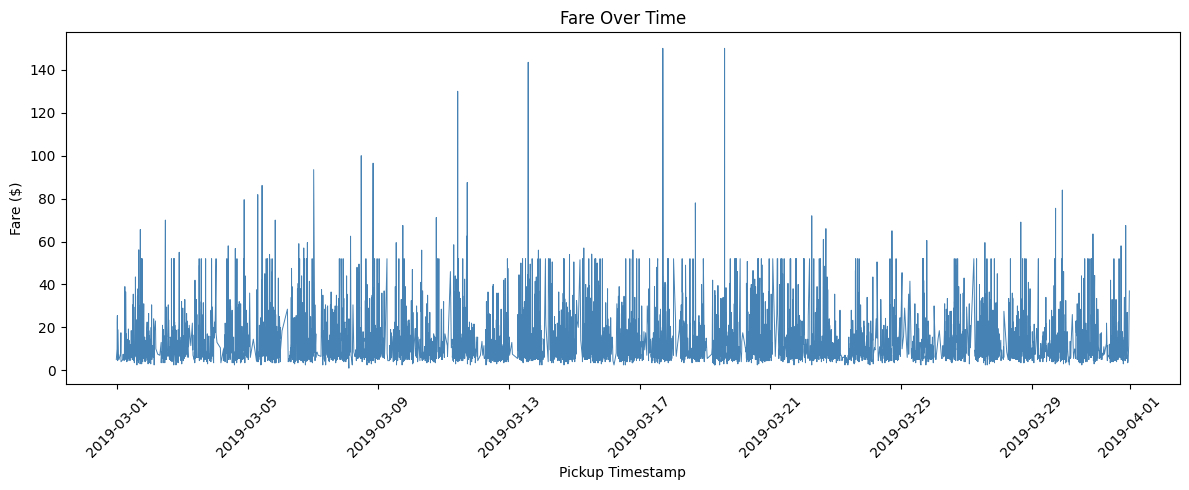

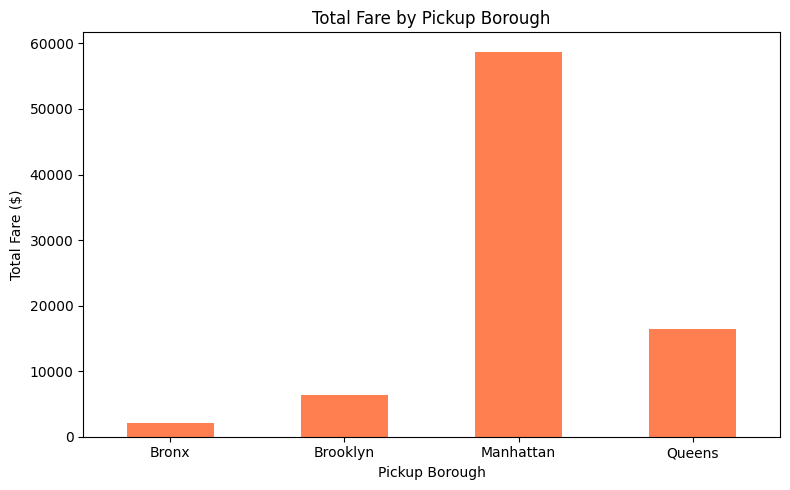

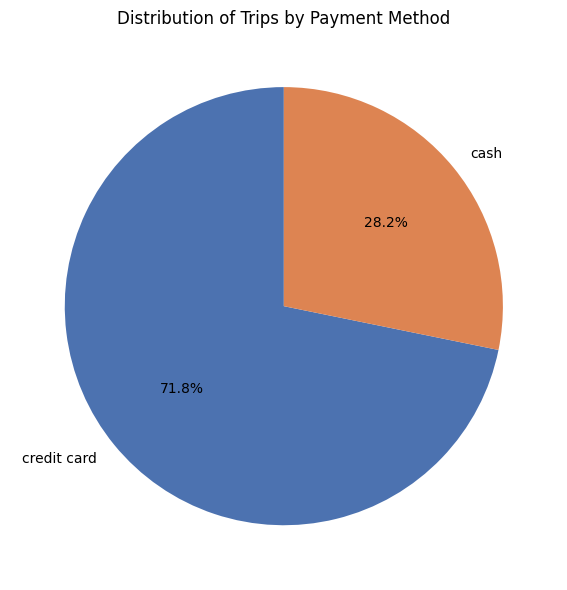

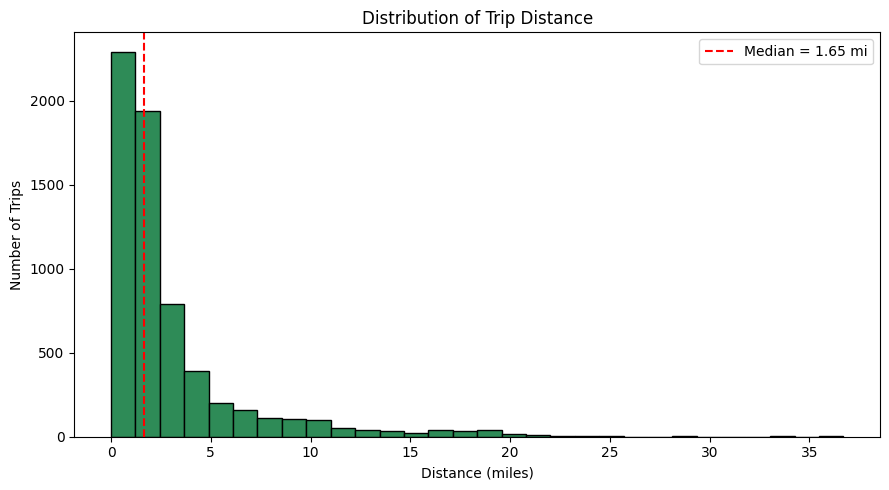

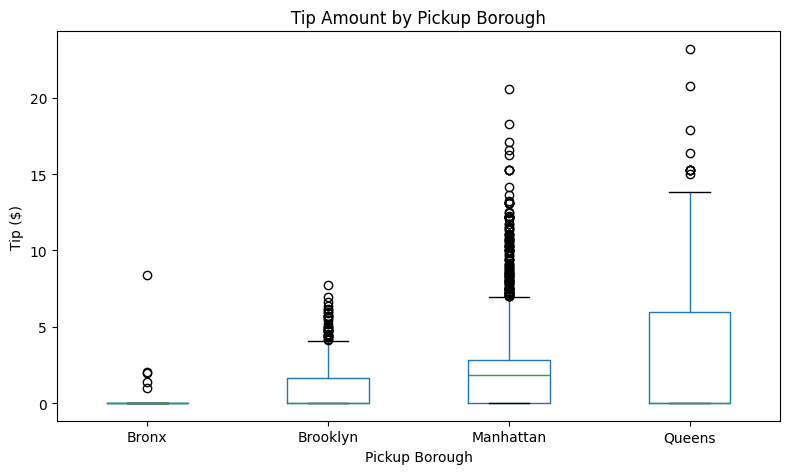

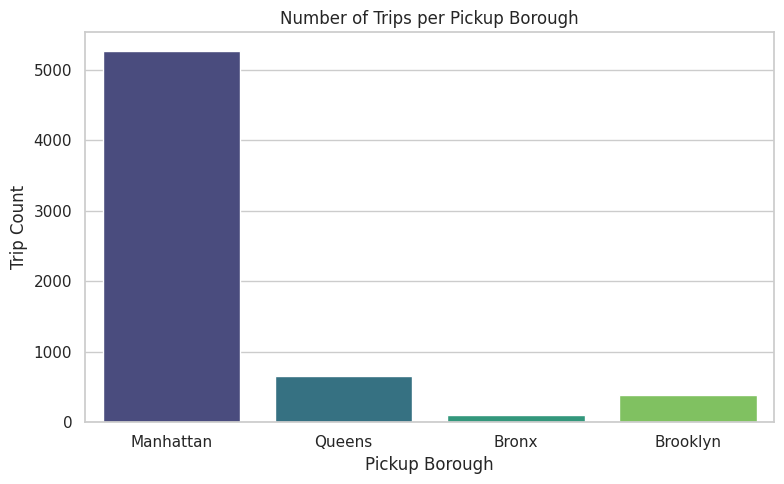

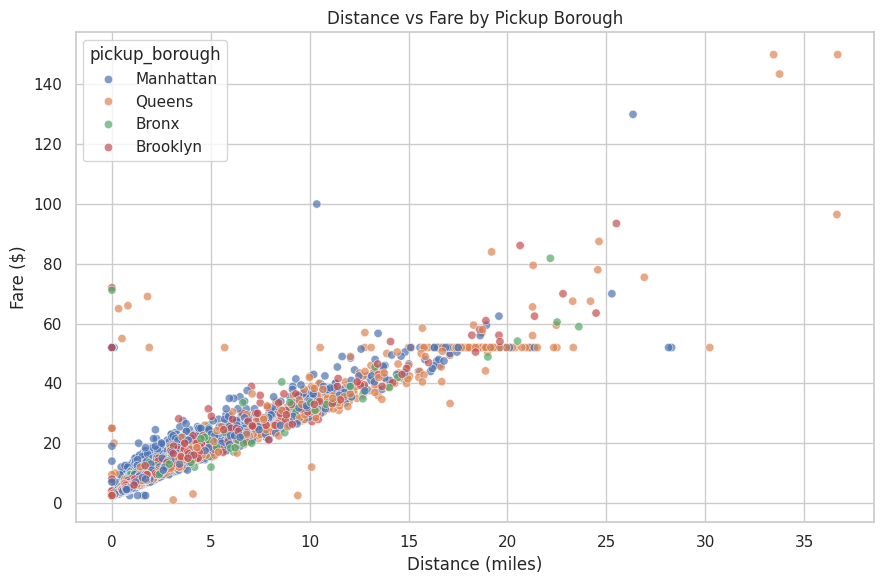

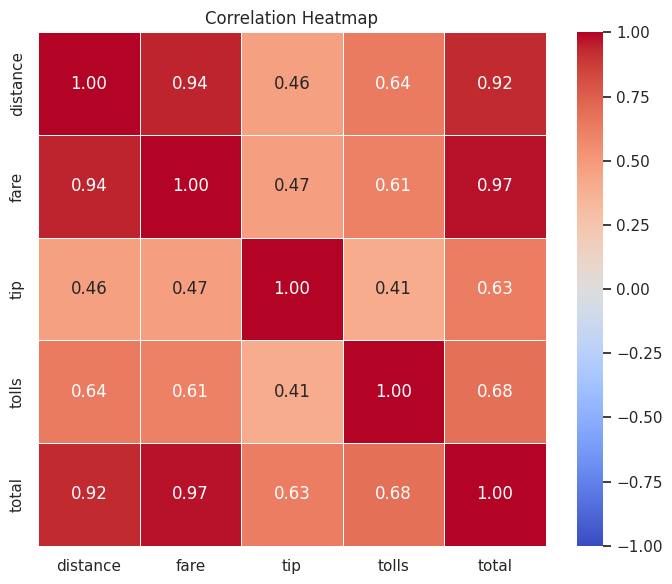

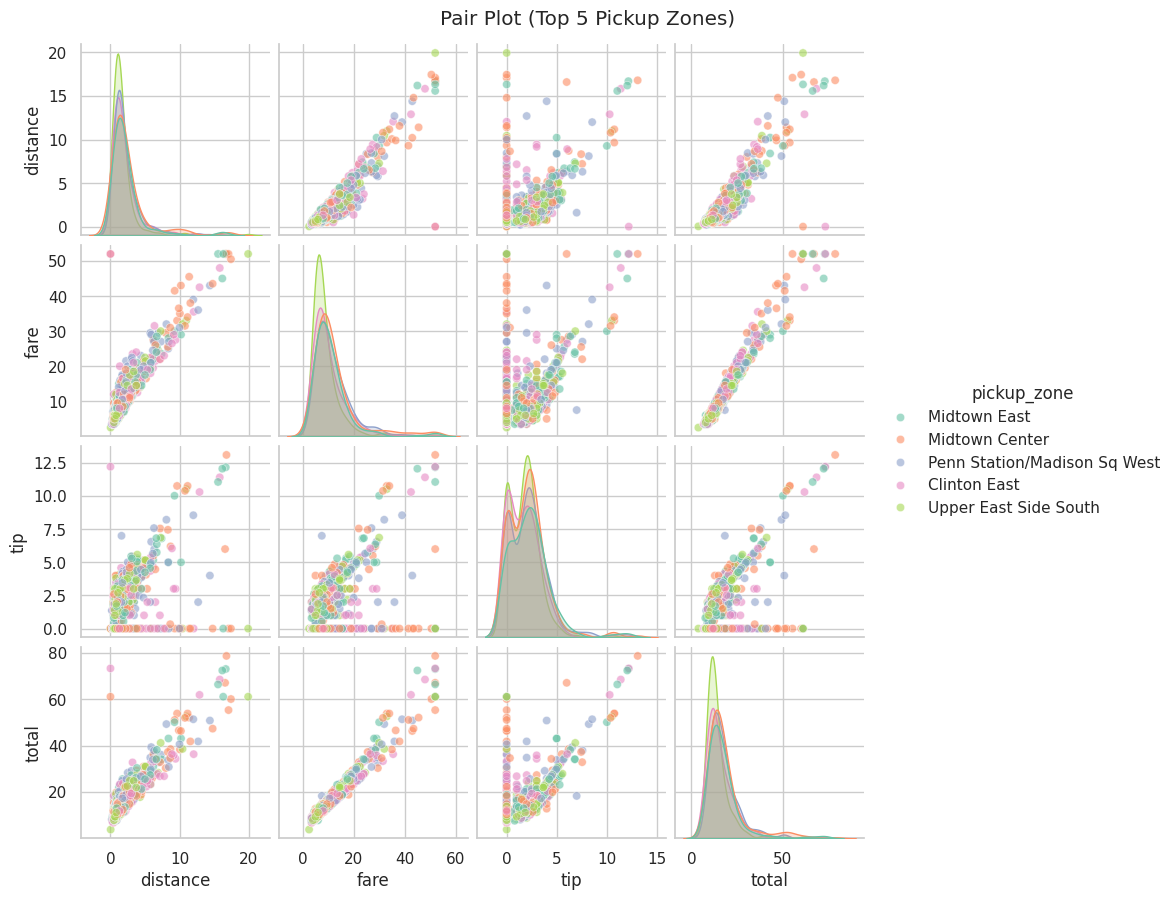

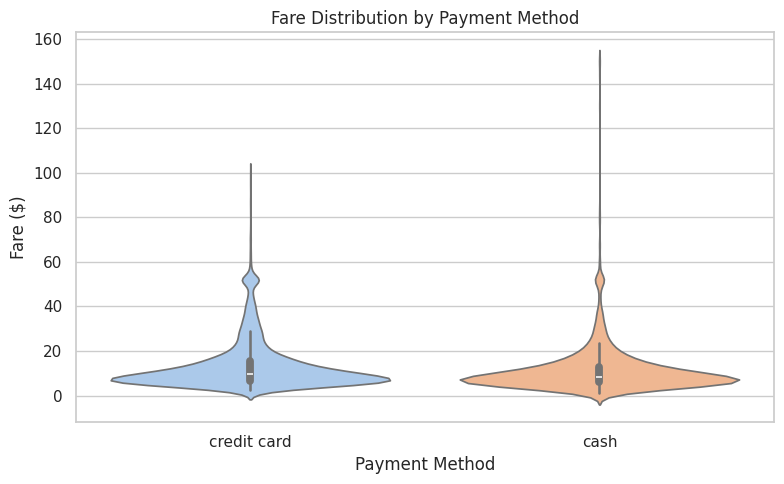

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# 1) LOADING THE DATASET

# load_dataset downloads the built-in 'taxis' sample from seaborn's repo
# and returns it as a pandas DataFrame.
df = sns.load_dataset("taxis")
print(df.shape)
print(df.head())
print(df.dtypes)


# 2) HANDLING MISSING VALUES

#     Check which columns have missing data.
#     isnull() gives True/False per cell, sum() counts the trues per column.
missing = df.isnull().sum()
print("\nMissing values per column:\n", missing[missing > 0])
# Expected: payment, pickup_zone, dropoff_zone, pickup_borough, dropoff_borough

#  Critical columns -> drop rows.
#     pickup_borough / pickup_zone are used directly in many plots
#     (bar, box, count, scatter colour, pair plot). Guessing them would
#     invent locations, so we remove those rows instead of imputing.
df = df.dropna(subset=["pickup_borough", "pickup_zone"])

#  Non-critical categorical columns -> impute with the MODE
#     (most frequent value). mode()[0] returns the most common value.
for col in ["payment", "dropoff_zone", "dropoff_borough"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numerical columns would be imputed with the median
# There are none missing here, but this loop makes the
# code safe for any numeric gaps.
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:", df.isnull().sum().sum())  # should be 0


# 3) VISUALIZATIONS USING MATPLOTLIB / PANDAS PLOT


# ---------------------------------------------------------------------
# Line chart: fare over time
# ---------------------------------------------------------------------
# 'pickup' is stored as text/object in some versions, so convert it to
# real datetime values. Sorting by time makes the line run left->right
# instead of zig-zagging back and forth.
df["pickup"] = pd.to_datetime(df["pickup"])
df_time = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(df_time["pickup"], df_time["fare"], linewidth=0.7, color="steelblue")
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Interpretation: fares fluctuate trip to trip with occasional spikes
# (long trips); there is no strong upward/downward trend over the month.

# ---------------------------------------------------------------------
# Bar chart: total fare per pickup_borough
# ---------------------------------------------------------------------
# groupby splits rows by borough; sum() adds fares inside each group.
# observed=True avoids warnings if the column is categorical dtype.
fare_by_borough = df.groupby("pickup_borough", observed=True)["fare"].sum()

fare_by_borough.plot(kind="bar", color="coral", figsize=(8, 5))
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
# Interpretation: Manhattan dominates because most trips start there.

# ---------------------------------------------------------------------
# Pie chart: trip share by payment method
# ---------------------------------------------------------------------
# value_counts() = number of trips per payment type -> one slice each.
# autopct prints each slice's percentage.
df["payment"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", startangle=90,
    figsize=(6, 6), colors=["#4c72b0", "#dd8452", "#55a868"]
)
plt.title("Distribution of Trips by Payment Method")
plt.ylabel("")          # remove the default y-label ("count")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# Histogram: distribution of distance
# ---------------------------------------------------------------------
# bins=30 gives finer granularity than the default 10. The data is
# right-skewed (many short trips, few long ones), so the median line
# helps readers see where the "typical" trip is.
plt.figure(figsize=(9, 5))
plt.hist(df["distance"], bins=30, color="seagreen", edgecolor="black")
plt.axvline(df["distance"].median(), color="red", linestyle="--",
            label=f"Median = {df['distance'].median():.2f} mi")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# Box plot: tip by pickup_borough
# ---------------------------------------------------------------------
# pandas boxplot: 'column' = numeric axis, 'by' = categorical axis.
# Box = middle 50% of tips, line = median, dots = outliers.
df.boxplot(column="tip", by="pickup_borough", figsize=(8, 5), grid=False)
plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")        # pandas adds an extra automatic title; remove it
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()


# VISUALIZATIONS USING SEABORN

sns.set_theme(style="whitegrid")   # clean default look for all seaborn plots

# ---------------------------------------------------------------------
# Count plot: number of trips per pickup_borough
# ---------------------------------------------------------------------
# countplot counts rows per category automatically (no groupby needed).
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough", hue="pickup_borough",
              palette="viridis", legend=False)
plt.title("Number of Trips per Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Trip Count")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# Scatter plot: distance vs fare, coloured by borough
# ---------------------------------------------------------------------
# hue= colours each point by borough. alpha makes points semi-transparent
# so overlapping dots are still visible.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare",
                hue="pickup_borough", alpha=0.7)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()
# Interpretation: strong positive linear relationship - longer trips cost more.

# ---------------------------------------------------------------------
# Heatmap: correlation matrix
# ---------------------------------------------------------------------
# .corr() computes Pearson correlation (-1 to +1) between every pair of
# the chosen numeric columns. annot=True prints the values in the cells.
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
# Interpretation: fare, distance and total are almost perfectly correlated;
# tip correlates moderately; tolls correlates weakly.

# ---------------------------------------------------------------------
# Pair plot: distance, fare, tip, total coloured by pickup_zone
# ---------------------------------------------------------------------
# There are ~190 pickup zones - colouring by all of them would make an
# unreadable plot with a huge legend. So we keep only the 5 busiest zones
# (still "comparing how different zones affect the variables").
top_zones = df["pickup_zone"].value_counts().head(5).index
df_top = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(df_top, vars=["distance", "fare", "tip", "total"],
             hue="pickup_zone", palette="Set2",
             plot_kws={"alpha": 0.6}, height=2.2)
plt.suptitle("Pair Plot (Top 5 Pickup Zones)", y=1.02)
plt.show()
# Diagonal = distribution of each variable per zone;
# off-diagonal = scatter plots of each pair of variables.

# ---------------------------------------------------------------------
# Violin plot: fare distribution per payment method
# ---------------------------------------------------------------------
# A violin combines a box plot with a smoothed density curve: wider parts
# mean more trips at that fare. inner="box" draws the quartiles inside.
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="payment", y="fare", hue="payment",
               palette="pastel", inner="box", legend=False)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()